In [ ]:
import pandas as pd
import sqlalchemy
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import BertTokenizer, BertForSequenceClassification
from sklearn.preprocessing import LabelEncoder
from tqdm import tqdm
from torch.cuda.amp import autocast
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import confusion_matrix
import numpy as np

In [7]:
# Datenbankverbindung
engine = sqlalchemy.create_engine('mysql+mysqlconnector://root@localhost/test')

# Artikel und Autoren auslesen
query = """
SELECT a.id as article_id, a.content, auth.name as author
FROM articles a
JOIN placeholder p ON a.id = p.article_id
JOIN authors auth ON p.author_id = auth.id
"""
df = pd.read_sql(query, engine)
df = df[df['author'] != 'kein Autor']

# Nur Autoren mit ≥10 Artikeln
author_counts = df['author'].value_counts()
authors_filtered = author_counts[author_counts >= 10].index
df = df[df['author'].isin(authors_filtered)]

In [8]:

# Label Encoding
label_encoder = LabelEncoder()
df['author_id'] = label_encoder.fit_transform(df['author'])

In [14]:
import torch
print(torch.cuda.is_available())  # → Muss True sein
print(torch.cuda.get_device_name(0))  # Zeigt dir die verwendete GPU



True
NVIDIA GeForce RTX 4070 SUPER


In [9]:
# Dataset vorbereiten
class TextDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=512):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.texts.iloc[idx],
            truncation=True,
            padding='max_length',
            max_length=self.max_length,
            return_tensors="pt"
        )
        return {
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten(),
            'labels': torch.tensor(self.labels.iloc[idx], dtype=torch.long)
        }


In [10]:
# Tokenizer & Modell laden
checkpoint_path = "./author_classification2/checkpoint-61620"
model = BertForSequenceClassification.from_pretrained(checkpoint_path)
tokenizer = BertTokenizer.from_pretrained(checkpoint_path)

# Dataset und DataLoader
dataset = TextDataset(df['content'], df['author_id'], tokenizer)
dataloader = DataLoader(dataset, batch_size=8)


In [15]:
from tqdm import tqdm
from torch.cuda.amp import autocast

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

all_preds, all_labels = [], []

with torch.no_grad():
    for batch in tqdm(dataloader, desc="Predicting"):  # Fortschrittsbalken
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        with autocast():  # Optional: Mixed Precision (wenn CUDA)
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            preds = torch.argmax(outputs.logits, axis=1)

        all_preds.extend(preds.cpu().tolist())   # Vorhersagen sammeln
        all_labels.extend(labels.cpu().tolist()) # Echte Labels sammeln


Predicting:   0%|          | 0/26512 [00:00<?, ?it/s]C:\Users\Daniel\AppData\Local\Temp\ipykernel_47408\912552312.py:16: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():  # Optional: Mixed Precision (wenn CUDA)
Predicting: 100%|██████████| 26512/26512 [29:49<00:00, 14.81it/s]  


In [16]:
import pandas as pd
import sqlalchemy
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import BertTokenizer, BertForSequenceClassification
from sklearn.preprocessing import LabelEncoder
from tqdm import tqdm
from torch.cuda.amp import autocast
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import confusion_matrix
import numpy as np

# DataFrame mit Ergebnissen
df['predicted'] = all_preds

# Accuracy pro Autor
df['correct'] = (df['author_id'] == df['predicted']).astype(int)
accuracy_per_author = df.groupby('author_id').agg(
    accuracy=('correct', 'mean'),
    article_count=('article_id', 'count')
).reset_index()

C:\Users\Daniel\AppData\Local\Temp\ipykernel_47408\3194552540.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  acc_per_author = df.groupby('author_id').apply(lambda x: accuracy_score(x['author_id'], x['predicted']))


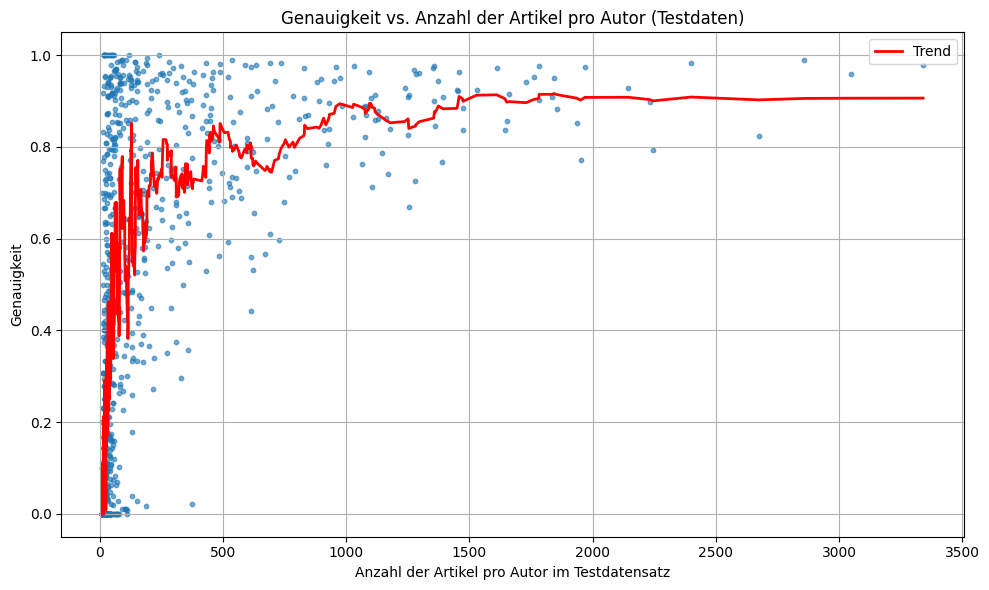

In [23]:
from sklearn.metrics import accuracy_score

acc_per_author = df.groupby('author_id').apply(lambda x: accuracy_score(x['author_id'], x['predicted']))
article_count = df.groupby('author_id').size()


# Accuracy-Darstellung mit Moving Average
plt.figure(figsize=(10, 6))
plt.scatter(article_count, acc_per_author, s=10, alpha=0.6)

# Trendlinie als Moving Average (sortierte Werte)
sorted_counts = article_count.sort_values()
sorted_acc = acc_per_author[sorted_counts.index]

window = 15
rolling_avg = sorted_acc.rolling(window=window, min_periods=1).mean()
plt.plot(sorted_counts.values, rolling_avg.values, color='red', label='Trend', linewidth=2)

plt.title("Genauigkeit vs. Anzahl der Artikel pro Autor (Testdaten)")
plt.xlabel("Anzahl der Artikel pro Autor im Testdatensatz")
plt.ylabel("Genauigkeit")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("accuracy_vs_article_count.png", dpi=300)
plt.show()

C:\Users\Daniel\AppData\Local\Temp\ipykernel_47408\1580163337.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['true_encoded'] = df_filtered['author_id'].map(encoding_map)
C:\Users\Daniel\AppData\Local\Temp\ipykernel_47408\1580163337.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['pred_encoded'] = df_filtered['predicted'].map(encoding_map)


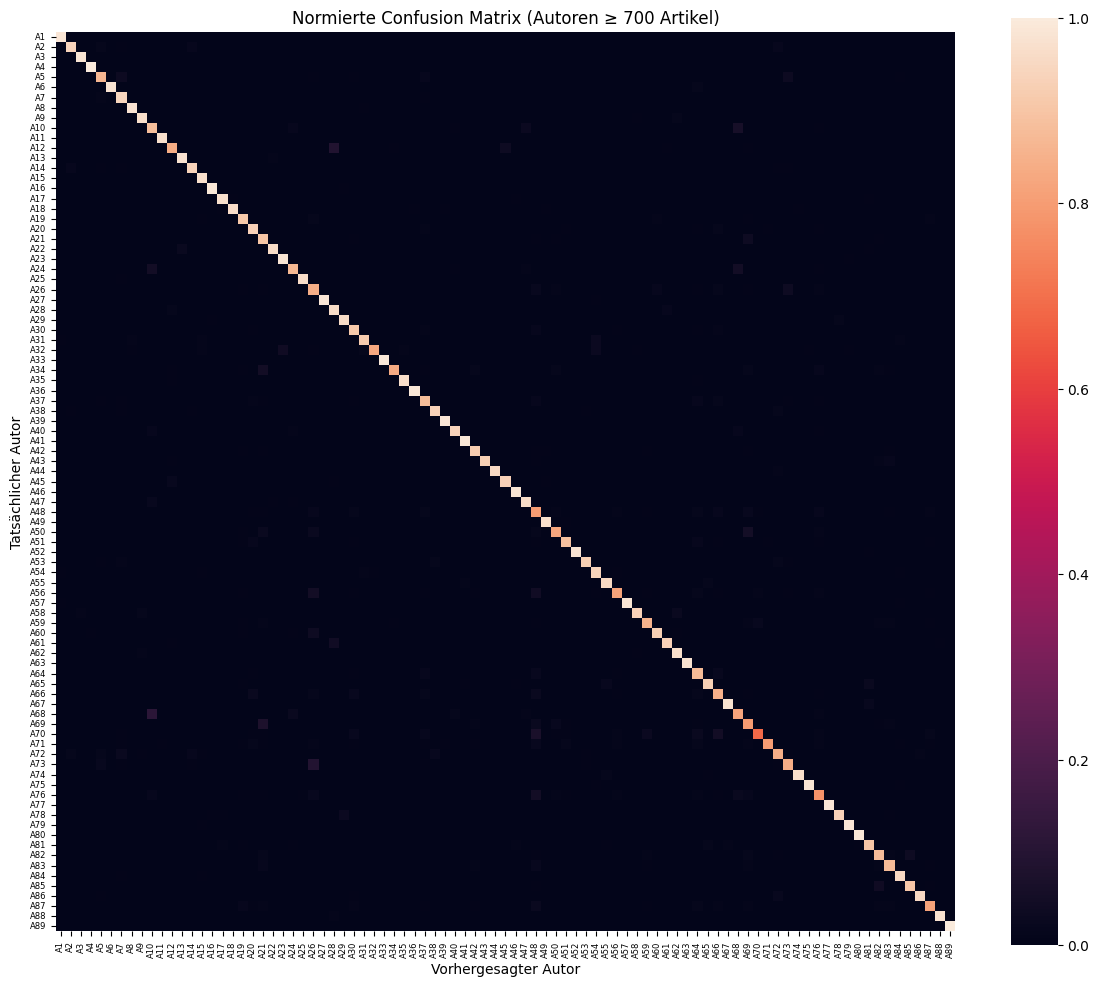

In [33]:
# 2. Plot: Confusion Matrix für Autoren mit ≥700 Artikeln
author_counts = df['author_id'].value_counts()
valid_authors = author_counts[author_counts >= 700].index
df_filtered = df[df['author_id'].isin(valid_authors)]

# Encoding der Autoren
unique_authors = sorted(df_filtered['author_id'].unique())
encoding_map = {author_id: f"A{i+1}" for i, author_id in enumerate(unique_authors)}
df_filtered['true_encoded'] = df_filtered['author_id'].map(encoding_map)
df_filtered['pred_encoded'] = df_filtered['predicted'].map(encoding_map)

# ➕ Fix: Entferne alle Zeilen mit fehlenden Encodings (z. B. bei ungültiger Vorhersage)
df_filtered = df_filtered.dropna(subset=['true_encoded', 'pred_encoded'])

# Confusion Matrix
cm = confusion_matrix(
    df_filtered['true_encoded'],
    df_filtered['pred_encoded'],
    labels=list(encoding_map.values()),
    normalize='true'
)

# Plot
plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    cmap="rocket",
    cbar=True,
    square=True,
    xticklabels=list(encoding_map.values()),
    yticklabels=list(encoding_map.values()),
    vmin=0, vmax=1  # Farblegende geht von 0 (schlecht) bis 1 (perfekt)
)

plt.xlabel("Vorhergesagter Autor", fontsize=10)
plt.ylabel("Tatsächlicher Autor", fontsize=10)
plt.xticks(rotation=90, fontsize=6)
plt.yticks(rotation=0, fontsize=6)
plt.title("Normierte Confusion Matrix (Autoren ≥ 700 Artikel)", fontsize=12)
plt.tight_layout()
plt.savefig("normalized_confusion_matrix.png", dpi=300)
plt.show()



C:\Users\Daniel\AppData\Local\Temp\ipykernel_47408\3191802373.py:13: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: accuracy_score(x['author_id'], x['predicted']))


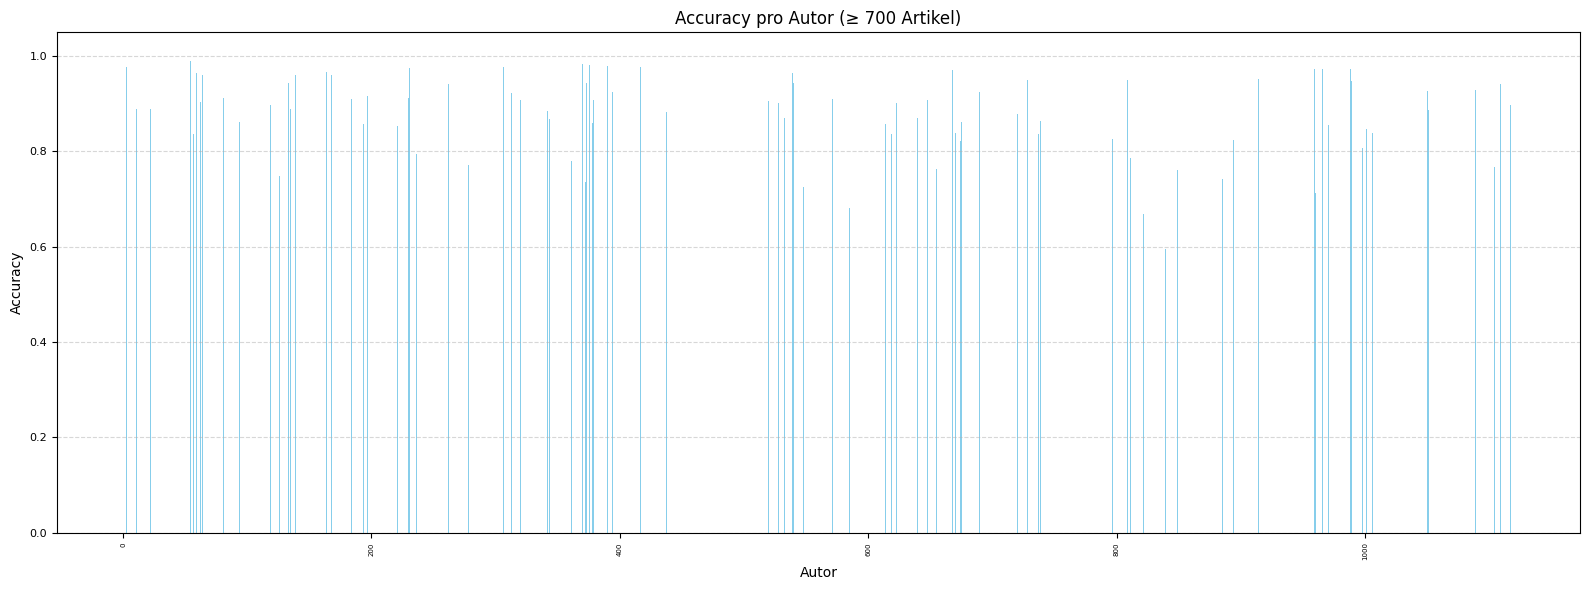

In [39]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import accuracy_score

# 1. Autoren mit ≥700 Artikeln filtern
author_counts = df['author_id'].value_counts()
valid_authors = author_counts[author_counts >= 700].index
df_filtered = df[df['author_id'].isin(valid_authors)].copy()

# 2. Accuracy pro Autor berechnen
accuracy_per_author = (
    df_filtered.groupby('author_id')
    .apply(lambda x: accuracy_score(x['author_id'], x['predicted']))
    .reset_index(name='accuracy')
)

# 3. Autorennamen holen
# Falls du eine author_id → name Zuordnung hast (z. B. in einem Dictionary oder DataFrame), bitte hier zuordnen:
# Beispiel: author_id_to_name = {123: "M. Mustermann", ...}
# accuracy_per_author['author_name'] = accuracy_per_author['author_id'].map(author_id_to_name)

# Falls author_id schon Name ist:
accuracy_per_author['author_name'] = accuracy_per_author['author_id']

# 4. Sortieren nach Name
accuracy_per_author = accuracy_per_author.sort_values('author_name')

# 5. Schriftgröße dynamisch setzen
num_authors = len(accuracy_per_author)
if num_authors <= 40:
    fontsize = 9
elif num_authors <= 80:
    fontsize = 7
else:
    fontsize = 5

# 6. Plot: Balkendiagramm
plt.figure(figsize=(16, 6))
plt.bar(accuracy_per_author['author_name'], accuracy_per_author['accuracy'], color="skyblue")
plt.xticks(rotation=90, fontsize=fontsize)
plt.yticks(fontsize=8)
plt.ylim(0, 1.05)
plt.xlabel("Autor", fontsize=10)
plt.ylabel("Accuracy", fontsize=10)
plt.title("Accuracy pro Autor (≥ 700 Artikel)", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("accuracy_per_author_named_barchart.png", dpi=300)
plt.show()


C:\Users\Daniel\AppData\Local\Temp\ipykernel_47408\3247342155.py:18: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: accuracy_score(x['author_id'], x['predicted']))


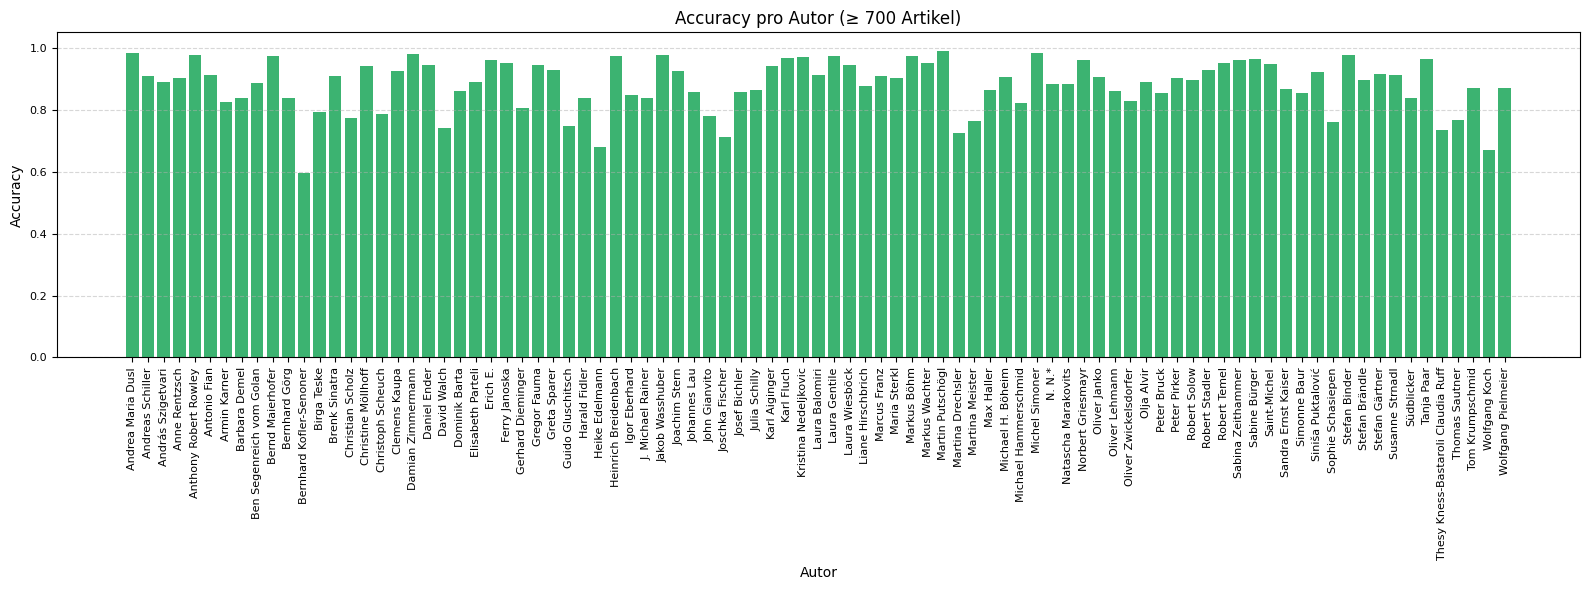

In [41]:
import pandas as pd
from sqlalchemy import create_engine

# Beispiel für SQLAlchemy Verbindung (anpassen falls nötig)
engine = create_engine('mysql+pymysql://root@localhost:3306/test')

# Autoren-Tabelle laden
authors_df = pd.read_sql("SELECT id, name FROM authors", con=engine)

# Autoren mit ≥700 Artikeln
author_counts = df['author_id'].value_counts()
valid_authors = author_counts[author_counts >= 700].index
df_filtered = df[df['author_id'].isin(valid_authors)].copy()

# Accuracy je Autor
accuracy_per_author = (
    df_filtered.groupby('author_id')
    .apply(lambda x: accuracy_score(x['author_id'], x['predicted']))
    .reset_index(name='accuracy')
)

# Namen dazujoinen
accuracy_with_names = accuracy_per_author.merge(authors_df, left_on='author_id', right_on='id')
accuracy_with_names = accuracy_with_names.sort_values("name")

# Dynamische Schriftgröße
num_authors = len(accuracy_with_names)
fontsize = 8 if num_authors > 80 else 7 if num_authors > 40 else 9

# Plot
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 6))
plt.bar(accuracy_with_names['name'], accuracy_with_names['accuracy'], color="mediumseagreen")
plt.xticks(rotation=90, fontsize=fontsize)
plt.yticks(fontsize=8)
plt.ylim(0, 1.05)
plt.xlabel("Autor", fontsize=10)
plt.ylabel("Accuracy", fontsize=10)
plt.title("Accuracy pro Autor (≥ 700 Artikel)", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("accuracy_per_author_named_barchart.png", dpi=300)
plt.show()
